# CNC Guard — 2. Fasea: Aurreprozesatzea eta Entrenamendua

**AABD Espezializazioa · 5071, 5072, 5073 moduluak**

Helburua: `ai4i2020_train.csv` datuetatik hutsegiteak iragarriko dituen eredu bat entrenatu eta `models/cnc_failure_model.pkl` gisa gorde.

## 1. Liburutegiak eta Karga

Beharrezko liburutegiak inportatu eta datuak kargatu.

In [10]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    PrecisionRecallDisplay, 
    precision_recall_curve,
    roc_auc_score
)

from imblearn.over_sampling import SMOTE
import joblib

# Datuen bidea
data_path = '../data/ai4i2020_train.csv'

if data_path is None:
    raise FileNotFoundError("Ez da 'ai4i2020_train.csv' fitxategia aurkitu data karpetan!")

# Datuak kargatu
df = pd.read_csv(data_path)

# 2. Lehenengo errenkadak ikusi
print("\n--- Lehenengo lerroak ---")
display(df.head())

# 3. Datu-multzoaren informazio orokorra
print("\n--- Dataset informazioa ---")
df.info()

# 4. Deskripzio estatistikoa
print("\n--- Deskripzio estatistikoa ---")
display(df.describe())

# 5. Balio nuloak egiaztatu
print("\n--- Balore nuloak ---")
print(df.isnull().sum())

# 6. Klase-inoreka aztertu
print("\n--- Helburu aldagaiaren banaketa (machine_failure) ---")
print(df['machine_failure'].value_counts(normalize=True) * 100)


--- Lehenengo lerroak ---


,machine_id,machine_type,air_temp_K,process_temp_K,rpm,torque_Nm,tool_wear_min,machine_failure,failure_TWF,failure_HDF,failure_PWF,failure_OSF,failure_RNF
0,CNC-024,M,302.0,310.9,1456,47.2,54,0,0,0,0,0,0
1,CNC-011,M,297.0,308.3,1399,46.4,132,0,0,0,0,0,1
2,CNC-030,M,301.0,311.6,1357,45.6,137,0,0,0,0,0,0
3,CNC-050,L,298.9,309.8,1411,56.3,84,0,0,0,0,0,0
4,CNC-040,L,297.1,308.5,1733,28.7,50,0,0,0,0,0,0



--- Dataset informazioa ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   machine_id       8000 non-null   object 
 1   machine_type     8000 non-null   object 
 2   air_temp_K       8000 non-null   float64
 3   process_temp_K   8000 non-null   float64
 4   rpm              8000 non-null   int64  
 5   torque_Nm        8000 non-null   float64
 6   tool_wear_min    8000 non-null   int64  
 7   machine_failure  8000 non-null   int64  
 8   failure_TWF      8000 non-null   int64  
 9   failure_HDF      8000 non-null   int64  
 10  failure_PWF      8000 non-null   int64  
 11  failure_OSF      8000 non-null   int64  
 12  failure_RNF      8000 non-null   int64  
dtypes: float64(3), int64(8), object(2)
memory usage: 812.6+ KB

--- Deskripzio estatistikoa ---


,air_temp_K,process_temp_K,rpm,torque_Nm,tool_wear_min,machine_failure,failure_TWF,failure_HDF,failure_PWF,failure_OSF,failure_RNF
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000
mean,300.005450,310.006062,1539.356875,40.003363,107.685000,0.033875,0.004500,0.01075,0.010250,0.010250,0.001875
std,1.996844,1.479432,180.982943,10.019546,63.612002,0.180919,0.066935,0.10313,0.100728,0.100728,0.043263
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,298.300000,308.800000,1422.000000,33.200000,53.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
50%,300.100000,310.100000,1503.000000,40.100000,107.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
75%,301.500000,311.100000,1613.000000,46.800000,163.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000



--- Balore nuloak ---
machine_id         0
machine_type       0
air_temp_K         0
process_temp_K     0
rpm                0
torque_Nm          0
tool_wear_min      0
machine_failure    0
failure_TWF        0
failure_HDF        0
failure_PWF        0
failure_OSF        0
failure_RNF        0
dtype: int64

--- Helburu aldagaiaren banaketa (machine_failure) ---
machine_failure
0    96.6125
1     3.3875
Name: proportion, dtype: float64


## 2. EDA — Datu-azterketa
Aztertu: zutabe motak eta balioen barrutiak, datu-balioen banaketa, korrelazioak

--- Sentsoreen balio-barrutiak (Min / Max / Batezbestekoa) ---


,min,mean,max,std
air_temp_K,295.3,300.005450,304.5,1.996844
process_temp_K,305.7,310.006062,313.8,1.479432
rpm,1168.0,1539.356875,2886.0,180.982943
torque_Nm,3.8,40.003363,76.6,10.019546
tool_wear_min,0.0,107.685000,253.0,63.612002


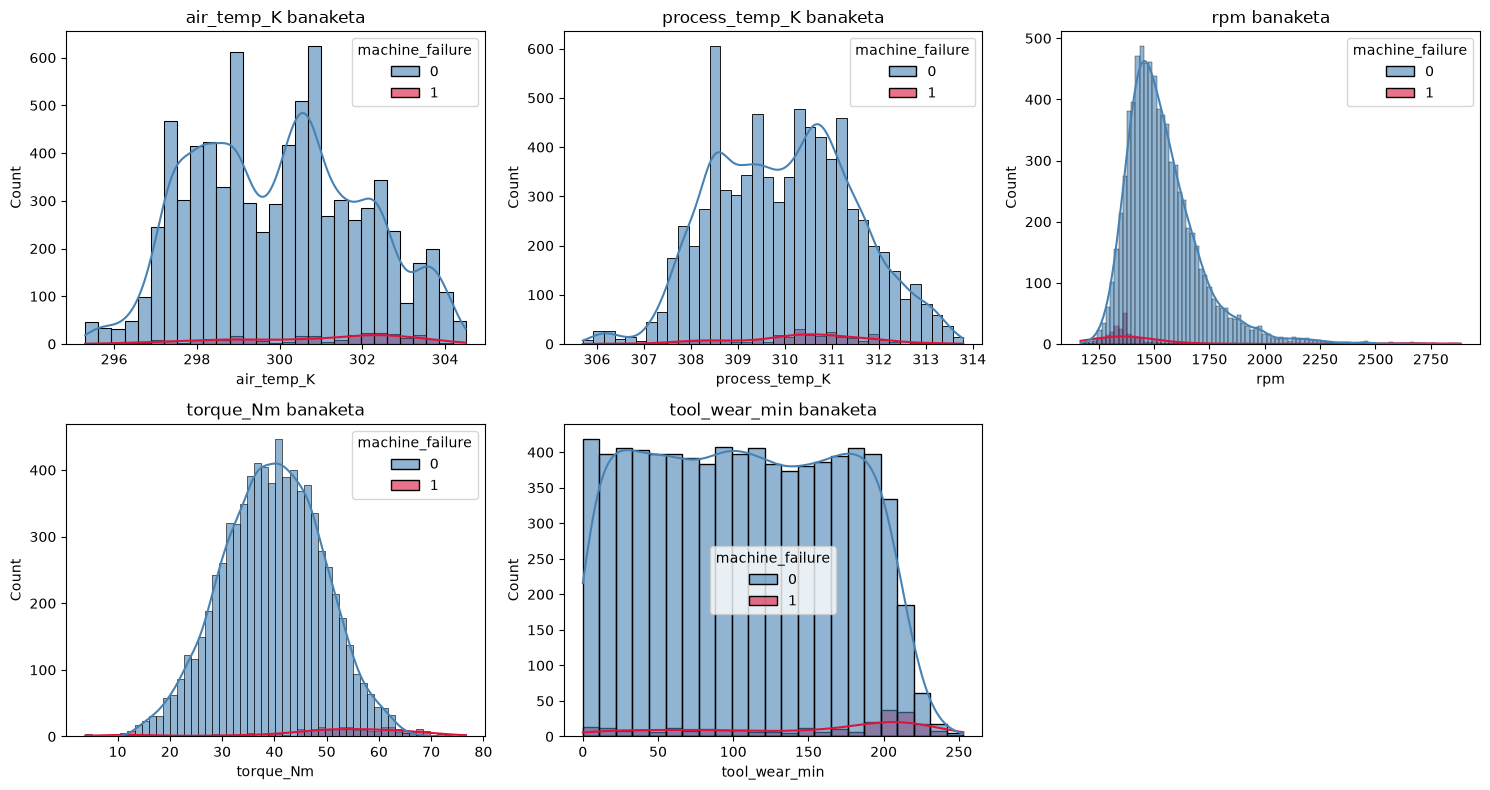

--- KLASE-BANAKETAREN ZENBAKETA ---
0 (Funtzionamendu egokia): 7729 makina (96.61%)
1 (Hutsegitea/Avaría):      271 makina (3.39%)


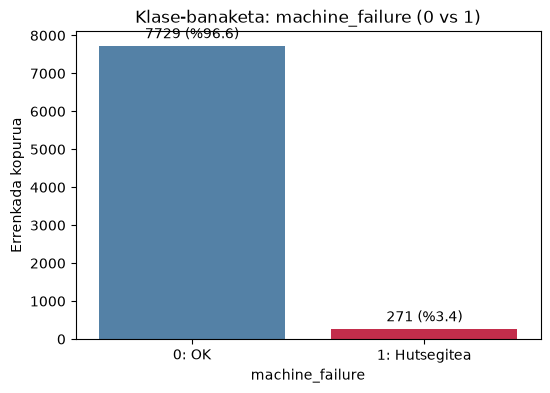


--- Hutsegite mota bakoitzaren kopuruak ---
failure_TWF    36
failure_HDF    86
failure_PWF    82
failure_OSF    82
failure_RNF    15
dtype: int64


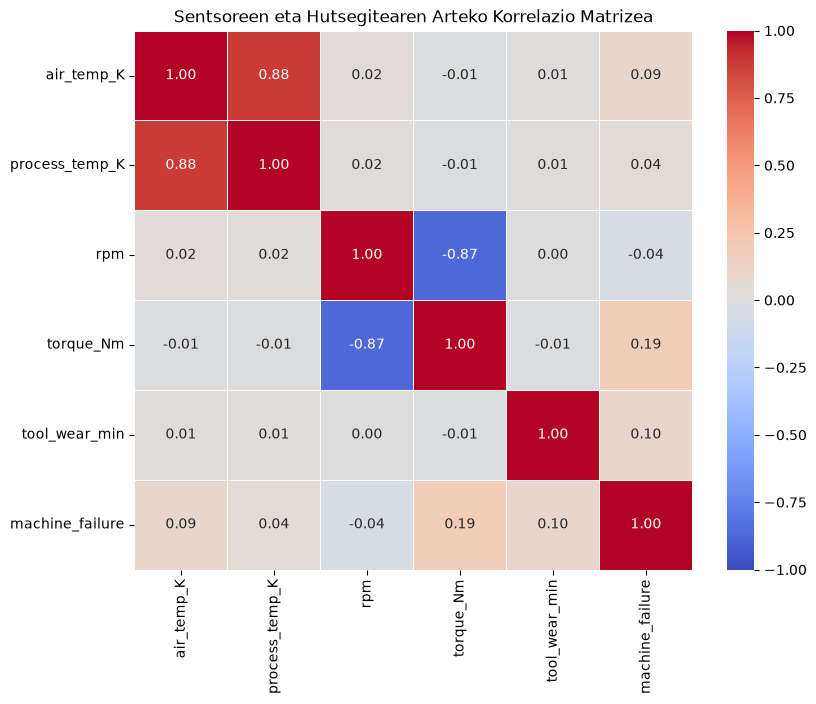


--- machine_failure-rekiko korrelazioa ---
machine_failure    1.000000
torque_Nm          0.190034
tool_wear_min      0.099214
air_temp_K         0.086001
process_temp_K     0.040849
rpm               -0.039966
Name: machine_failure, dtype: float64


In [11]:
# Sentsoreen ezaugarri numerikoak definitu
sensor_cols = ['air_temp_K', 'process_temp_K', 'rpm', 'torque_Nm', 'tool_wear_min']

print("--- Sentsoreen balio-barrutiak (Min / Max / Batezbestekoa) ---")
display(df[sensor_cols].describe().T[['min', 'mean', 'max', 'std']])

# Sentsoreen banaketa grafikoak (Histrogramak)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(sensor_cols):
    sns.histplot(data=df, x=col, hue='machine_failure', kde=True, ax=axes[i], palette={0: 'steelblue', 1: 'crimson'}, alpha=0.6)
    axes[i].set_title(f"{col} banaketa")

# Azken azpibista hutsik geratzen denez, ezkutatu
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

# KLASE-BANAKETA (machine_failure)
counts = df['machine_failure'].value_counts()
percentages = df['machine_failure'].value_counts(normalize=True) * 100

print("--- KLASE-BANAKETAREN ZENBAKETA ---")
print(f"0 (Funtzionamendu egokia): {counts[0]} makina ({percentages[0]:.2f}%)")
print(f"1 (Hutsegitea/Avaría):      {counts[1]} makina ({percentages[1]:.2f}%)")

# Klase-banaketaren grafikoa
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=['steelblue', 'crimson'], legend=False)
plt.title("Klase-banaketa: machine_failure (0 vs 1)")
plt.xlabel("machine_failure")
plt.ylabel("Errenkada kopurua")
plt.xticks([0, 1], ['0: OK', '1: Hutsegitea'])

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} (%{p.get_height()/len(df)*100:.1f})',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                textcoords='offset points')
plt.show()

# PUNTU GEHIGARRIA: Hutsegite moten xehetasuna (TWF, HDF, PWF, OSF, RNF)
failure_cols = ['failure_TWF', 'failure_HDF', 'failure_PWF', 'failure_OSF', 'failure_RNF']
print("\n--- Hutsegite mota bakoitzaren kopuruak ---")
print(df[failure_cols].sum())

# EZAUGARRIEN ARTEKO KORRELAZIOA
plt.figure(figsize=(9, 7))
corr_matrix = df[sensor_cols + ['machine_failure']].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Sentsoreen eta Hutsegitearen Arteko Korrelazio Matrizea")
plt.show()

# machine_failure-rekin korrelazio altuena dutenak bistaratu
print("\n--- machine_failure-rekiko korrelazioa ---")
print(corr_matrix['machine_failure'].sort_values(ascending=False))

## 3. Aurreprozesatzea
Prestatu datuak entrenamendurako, feature engineering...

In [12]:
# 1. Ezaugarri ez-iragarleak (ID) eta isurpena (data leakage) sortzen duten zutabeak kendu
drop_cols = ['machine_id', 'failure_TWF', 'failure_HDF', 'failure_PWF', 'failure_OSF', 'failure_RNF']
df_clean = df.drop(columns=drop_cols)

# 2. Aldagai kategorialak One-Hot Encoding bidez kodetu ('machine_type')
df_encoded = pd.get_dummies(df_clean, columns=['machine_type'], drop_first=True)

# 3. X (ezaugarriak) eta y (helburua) banandu
X = df_encoded.drop(columns=['machine_failure'])
y = df_encoded['machine_failure']

print(f"X forma: {X.shape}")
print(f"y forma: {y.shape}")
print("\n--- X-ren lehenengo errenkadak ---")
display(X.head())

X forma: (8000, 7)
y forma: (8000,)

--- X-ren lehenengo errenkadak ---


,air_temp_K,process_temp_K,rpm,torque_Nm,tool_wear_min,machine_type_L,machine_type_M
0,302.0,310.9,1456,47.2,54,False,True
1,297.0,308.3,1399,46.4,132,False,True
2,301.0,311.6,1357,45.6,137,False,True
3,298.9,309.8,1411,56.3,84,True,False
4,297.1,308.5,1733,28.7,50,True,False


## 4. Train / Validation Zatiketa

In [14]:
# FEATURES aldagaia definitu — scoring-api-ak espero duen orden berdinean!
FEATURES = ['air_temp_K', 'process_temp_K', 'rpm', 'torque_Nm', 'tool_wear_min']

# Datu-multzoa entrenamendu eta balioztatze multzoetan banatu (%80 / %20)
# 'stratify=y' erabiltzea ezinbestekoa da klase-desoreka dela eta
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

smote = SMOTE(sampling_strategy=0.35, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Entrenamendu multzoa (X_train): {X_train.shape[0]} errenkada")
print(f"Balioztatze multzoa (X_val): {X_val.shape[0]} errenkada")


print("\n--- Helburuaren banaketa X_train-en (%) ---")
print(y_train.value_counts(normalize=True) * 100)

Entrenamendu multzoa (X_train): 6400 errenkada
Balioztatze multzoa (X_val): 1600 errenkada

--- Helburuaren banaketa X_train-en (%) ---
machine_failure
0    96.609375
1     3.390625
Name: proportion, dtype: float64


## 5. Entrenamendua

Eredu bat (gutxienez) entrenatu. Aukerakoa: hainbat eredu konparatu.

In [15]:
# Random Forest eredua sortu
model = RandomForestClassifier(
    n_estimators=2000,
    max_depth=18,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42
)

# Eredua entrenatu
model.fit(X_train_res, y_train_res)

print("Random Forest eredua entrenatu da.")

Random Forest eredua entrenatu da.


## 6. Ebaluazioa
Ebaluatu honako metrikekin:
- `classification_report` — precision, **recall**, f1-score
- `confusion_matrix` — bistaratu eta interpretatu
- `roc_auc_score`

> Zergatik da recall garrantzitsuagoa precision baino kasu honetan?

--- SAILKAPEN TXOSTENA (CLASSIFICATION REPORT) ---
                   precision    recall  f1-score   support

Ez hutsegitea (0)     0.9883    0.9819    0.9851      1546
   Hutsegitea (1)     0.5625    0.6667    0.6102        54

         accuracy                         0.9712      1600
        macro avg     0.7754    0.8243    0.7976      1600
     weighted avg     0.9739    0.9712    0.9724      1600


--- NAHASMEN-MATRIZEA (ATALASEA = 0.5) ---
[[1518   28]
 [  18   36]]
True Negatives (TN): 1518
False Positives (FP): 28
False Negatives (FN): 18
True Positives (TP): 36


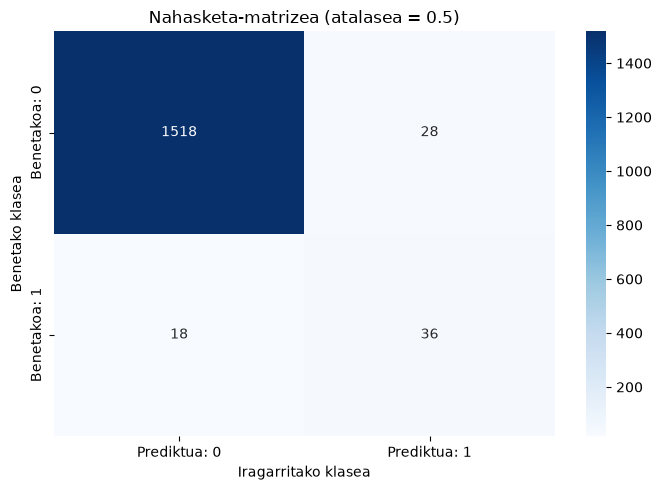


ROC-AUC: 0.9743

--- EMAITZEN INTERPRETAZIOA ---
Benetako hutsegite detektatuak (TP): 36
Hutsegite detektatu gabeak (FN): 18
Alerta faltsuak (FP): 28
Recall: 0.6667
Detektatu gabeko hutsegiteak: 33.33%

Recall-a garrantzitsua da, benetako hutsegiteetatik zenbat detektatzen diren neurtzen duelako. Mantentze prediktiboan, hutsegite bat ez detektatzeak makinaren geldialdia edo kalteak eragin ditzake.


In [16]:
# Klaseak aurreikusi, 0.5 atalase lehenetsia erabiliz
y_pred_05 = model.predict(X_val)

# SAILKAPEN-TXOSTENA
print("--- SAILKAPEN TXOSTENA (CLASSIFICATION REPORT) ---")
print(classification_report(
    y_val,
    y_pred_05,
    labels=[0, 1],
    target_names=['Ez hutsegitea (0)', 'Hutsegitea (1)'],
    digits=4,
    zero_division=0
))

# NAHASMEN-MATRIZEA
cm_05 = confusion_matrix(y_val, y_pred_05, labels=[0, 1])

print("\n--- NAHASMEN-MATRIZEA (ATALASEA = 0.5) ---")
print(cm_05)

# MATRIZEAREN EMAITZAK ATERA
tn, fp, fn, tp = cm_05.ravel()

print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")

# NAHASMEN-MATRIZEA IRUDIKATU
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_05,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Prediktua: 0', 'Prediktua: 1'],
    yticklabels=['Benetakoa: 0', 'Benetakoa: 1']
)

plt.xlabel('Iragarritako klasea')
plt.ylabel('Benetako klasea')
plt.title('Nahasketa-matrizea (atalasea = 0.5)')
plt.tight_layout()
plt.show()

# ROC-AUC KALKULATU
y_probs = model.predict_proba(X_val)[:, 1]
roc_auc = roc_auc_score(y_val, y_probs)

print(f"\nROC-AUC: {roc_auc:.4f}")

# RECALL-AREN GARRANTZIA AZALDU
print("\n--- EMAITZEN INTERPRETAZIOA ---")
print(f"Benetako hutsegite detektatuak (TP): {tp}")
print(f"Hutsegite detektatu gabeak (FN): {fn}")
print(f"Alerta faltsuak (FP): {fp}")

if (tp + fn) > 0:
    print(f"Recall: {tp / (tp + fn):.4f}")
    print(f"Detektatu gabeko hutsegiteak: {fn / (tp + fn) * 100:.2f}%")

print(
    "\nRecall-a garrantzitsua da, benetako hutsegiteetatik "
    "zenbat detektatzen diren neurtzen duelako. "
    "Mantentze prediktiboan, hutsegite bat ez detektatzeak "
    "makinaren geldialdia edo kalteak eragin ditzake."
)



## 6b. Atalasearen Doikuntza (Threshold Tuning)

Atalase lehenetsiak (0.5) Negatibo Faltsu (FN) gehiegi uzten baditu, saiatu atalasea jaisten (adib. 0.20 edo 0.15):
- Erabili predict_proba probabilitateak lortzeko.
- Marraztu Precision-Recall kurba (PrecisionRecallDisplay) atalase optimoa aukeratzeko.
- Aplikatu atalase berria eta atera berriro classification_report eta confusion_matrix.

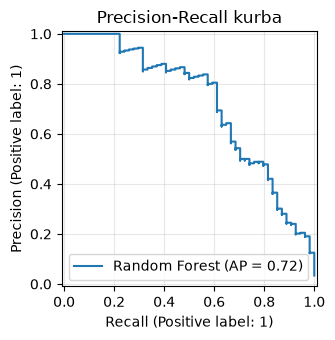

--- ATALASE OPTIMOA (F1-SCORE) ---
Atalasea:  0.6508
Precision: 0.8049
Recall:    0.6111
F1-score:  0.6947


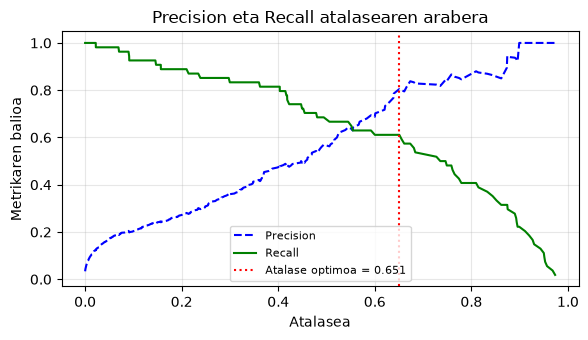


Erabilitako atalasea: 0.2500

--- SAILKAPEN TXOSTENA ---
                   precision    recall  f1-score   support

Ez hutsegitea (0)     0.9945    0.9340    0.9633      1546
   Hutsegitea (1)     0.3108    0.8519    0.4554        54

         accuracy                         0.9313      1600
        macro avg     0.6527    0.8929    0.7094      1600
     weighted avg     0.9714    0.9313    0.9462      1600


--- NAHASMEN-MATRIZEA ---
[[1444  102]
 [   8   46]]
True Negatives (TN): 1444
False Positives (FP): 102
False Negatives (FN): 8
True Positives (TP): 46


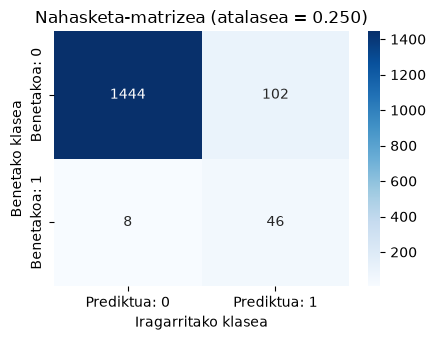


--- METRIKA NAGUSIAK ---
Precision: 0.3108
Recall:    0.8519
F1-score:  0.4554

Detektatu gabeko hutsegiteak: 8
Detektatu gabeko hutsegiteen ehunekoa: 14.81%

--- EMAITZEN INTERPRETAZIOA ---
Benetako hutsegite detektatuak (TP): 46
Hutsegite detektatu gabeak (FN): 8
Alerta faltsuak (FP): 102

Recall-a garrantzitsua da benetako hutsegiteak detektatzeko. Atalasea jaistean, recall-a handitu daiteke, baina alerta faltsu gehiago ere sor daitezke.


In [20]:
# HUTSEGITE-PROBABILITATEAK KALKULATU
y_probs = model.predict_proba(X_val)[:, 1]


# PRECISION-RECALL KURBA IRUDIKATU
from sklearn.metrics import PrecisionRecallDisplay, precision_recall_curve

fig, ax = plt.subplots(figsize=(5, 3.5))

PrecisionRecallDisplay.from_predictions(
    y_val,
    y_probs,
    name='Random Forest',
    ax=ax
)

ax.set_title('Precision-Recall kurba')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# PRECISION ETA RECALL ATALASEAREN ARABERA KALKULATU
precisions, recalls, thresholds = precision_recall_curve(y_val, y_probs)


# F1-SCORE HANDIENA DUEN ATALASEA AUKERATU
f1_scores = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-10)
)

best_index = f1_scores.argmax()
atalase_optimoa = thresholds[best_index]

print("--- ATALASE OPTIMOA (F1-SCORE) ---")
print(f"Atalasea:  {atalase_optimoa:.4f}")
print(f"Precision: {precisions[best_index]:.4f}")
print(f"Recall:    {recalls[best_index]:.4f}")
print(f"F1-score:  {f1_scores[best_index]:.4f}")


# PRECISION ETA RECALL GRAFIKATU
fig, ax = plt.subplots(figsize=(6, 3.5))

ax.plot(thresholds, precisions[:-1], "b--", label="Precision")
ax.plot(thresholds, recalls[:-1], "g-", label="Recall")

ax.axvline(
    atalase_optimoa,
    color="red",
    linestyle=":",
    label=f"Atalase optimoa = {atalase_optimoa:.3f}"
)

ax.set_xlabel("Atalasea")
ax.set_ylabel("Metrikaren balioa")
ax.set_title("Precision eta Recall atalasearen arabera")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ATALASEA AUKERATU
# None bada, F1-score handiena duen atalasea erabiliko da.
# Bestela, eskuz adierazitako atalasea erabiliko da.
# Adibideak: 0.20 edo 0.15

ATALASEA = 0.25

if ATALASEA is None:
    atalasea_erabilia = atalase_optimoa
else:
    atalasea_erabilia = ATALASEA


# ATALASE BERRIA APLIKATU
y_pred_berria = (y_probs >= atalasea_erabilia).astype(int)

print(f"\nErabilitako atalasea: {atalasea_erabilia:.4f}")


# SAILKAPEN-TXOSTENA
print("\n--- SAILKAPEN TXOSTENA ---")

print(classification_report(
    y_val,
    y_pred_berria,
    labels=[0, 1],
    target_names=['Ez hutsegitea (0)', 'Hutsegitea (1)'],
    digits=4,
    zero_division=0
))


# NAHASMEN-MATRIZEA
cm_berria = confusion_matrix(
    y_val,
    y_pred_berria,
    labels=[0, 1]
)

print("\n--- NAHASMEN-MATRIZEA ---")
print(cm_berria)

tn, fp, fn, tp = cm_berria.ravel()

print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")


# NAHASMEN-MATRIZEA IRUDIKATU
fig, ax = plt.subplots(figsize=(4.5, 3.5))

sns.heatmap(
    cm_berria,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Prediktua: 0', 'Prediktua: 1'],
    yticklabels=['Benetakoa: 0', 'Benetakoa: 1'],
    annot_kws={"size": 10},
    ax=ax
)

ax.set_xlabel('Iragarritako klasea')
ax.set_ylabel('Benetako klasea')
ax.set_title(f'Nahasketa-matrizea (atalasea = {atalasea_erabilia:.3f})')

plt.tight_layout()
plt.show()


# METRIKA NAGUSIAK KALKULATU
precision_berria = precision_score(
    y_val, y_pred_berria, zero_division=0
)

recall_berria = recall_score(
    y_val, y_pred_berria, zero_division=0
)

f1_berria = f1_score(
    y_val, y_pred_berria, zero_division=0
)

print("\n--- METRIKA NAGUSIAK ---")
print(f"Precision: {precision_berria:.4f}")
print(f"Recall:    {recall_berria:.4f}")
print(f"F1-score:  {f1_berria:.4f}")


# DETEKTATU GABEKO HUTSEGITEAK KALKULATU
hutsegite_kop = tp + fn

if hutsegite_kop > 0:
    detektatu_gabeak = fn / hutsegite_kop * 100

    print(f"\nDetektatu gabeko hutsegiteak: {fn}")
    print(
        "Detektatu gabeko hutsegiteen ehunekoa: "
        f"{detektatu_gabeak:.2f}%"
    )
else:
    print("\nEz dago benetako hutsegiterik balioztatze-multzoan.")


# EMAITZEN INTERPRETAZIOA
print("\n--- EMAITZEN INTERPRETAZIOA ---")
print(f"Benetako hutsegite detektatuak (TP): {tp}")
print(f"Hutsegite detektatu gabeak (FN): {fn}")
print(f"Alerta faltsuak (FP): {fp}")

print(
    "\nRecall-a garrantzitsua da benetako hutsegiteak "
    "detektatzeko. Atalasea jaistean, recall-a handitu "
    "daiteke, baina alerta faltsu gehiago ere sor daitezke."
)

## 7. Eredua Gorde

Scoring-api-k `/models/cnc_failure_model.pkl` bilatu behar du.

In [ ]:
# Eredua gordetzeko direktorioa sortu, beharrezkoa bada
os.makedirs("../models", exist_ok=True)

# Entrenatutako eredua fitxategi batean gorde
joblib.dump(model, "../models/cnc_failure_model.pkl")

print("Eredua behar bezala gorde da: ../models/cnc_failure_model.pkl")

# Gordetako eredua kargatu dela egiaztatu
eredu_kargatua = joblib.load("../models/cnc_failure_model.pkl")

print("Gordetako eredua behar bezala kargatu da.")